<a href="https://colab.research.google.com/github/dexter-llabCD/Dexter_activity_01_AI.ipynb/blob/main/dexter_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proactive Churn Prevention: Multi-Model Evaluation & Cost-Benefit Analysis

This section trains and evaluates three proactive classification models:
* **Logistic Regression**
* **Decision Tree Classifier**
* **Random Forest Classifier**

We will visualize their structures/boundaries, evaluate correct and incorrect predictions via confusion matrices, and run a detailed performance evaluation (covering Accuracy, Precision, Recall, and F1-Score) alongside a campaign simulation to determine the best model.

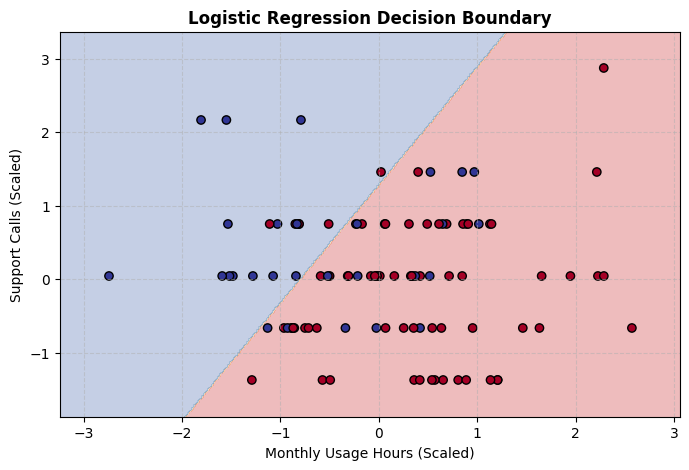

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# --- 1. MODEL TRAINING ---

# Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_log_pred = log_reg.predict(X_test_scaled)
y_log_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# Decision Tree
dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_dt_pred = dt_model.predict(X_test_scaled)

# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_rf_pred = rf_model.predict(X_test_scaled)

# --- 2. MODEL DIAGRAMS & VISUALIZATIONS ---

# Logistic Regression Boundary Plot
x_min, x_max = X_test_scaled[:, 0].min() - 0.5, X_test_scaled[:, 0].max() + 0.5
y_min, y_max = X_test_scaled[:, 1].min() - 0.5, X_test_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z_boundary = log_reg.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z_boundary, alpha=0.3, cmap='RdYlBu')
plt.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=y_test, cmap='RdYlBu', edgecolors='k')
plt.title('Logistic Regression Decision Boundary', fontweight='bold')
plt.xlabel('Monthly Usage Hours (Scaled)')
plt.ylabel('Support Calls (Scaled)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

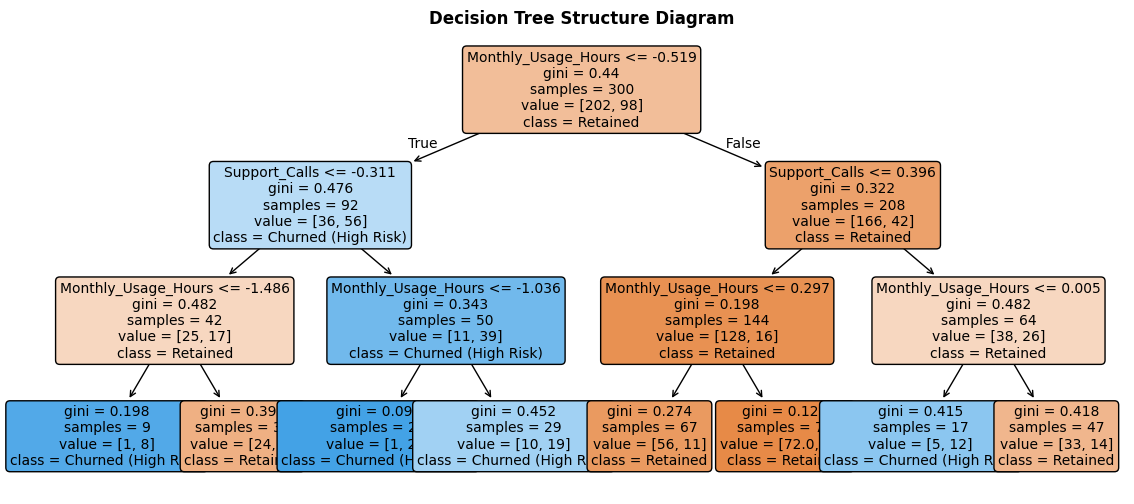

In [58]:
# Plot Decision Tree structure
plt.figure(figsize=(14, 6))
plot_tree(dt_model,
          feature_names=['Monthly_Usage_Hours', 'Support_Calls'],
          class_names=['Retained', 'Churned (High Risk)'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree Structure Diagram', fontweight='bold', fontsize=12)
plt.show()

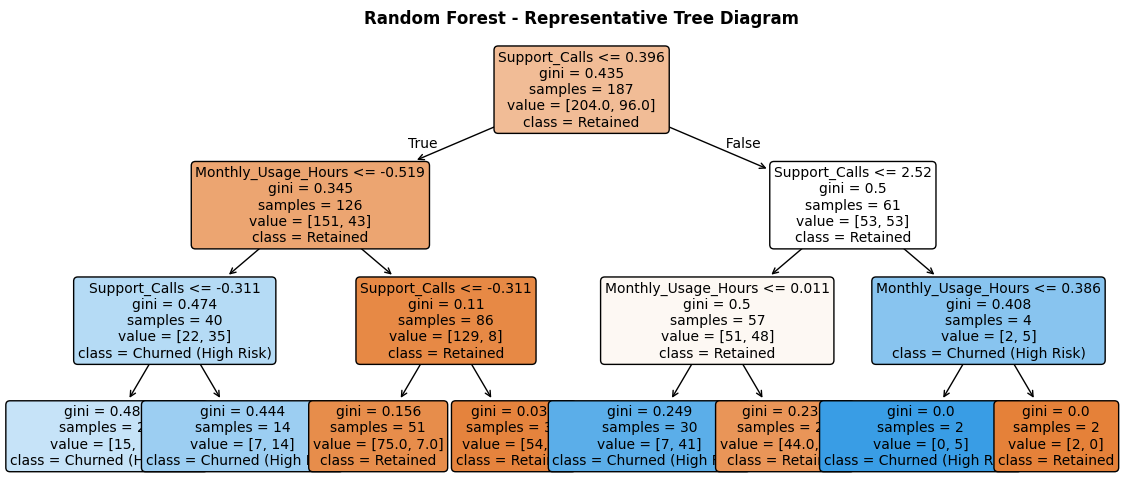

In [59]:
# Plot Random Forest Representative Estimator
plt.figure(figsize=(14, 6))
plot_tree(rf_model.estimators_[0],
          feature_names=['Monthly_Usage_Hours', 'Support_Calls'],
          class_names=['Retained', 'Churned (High Risk)'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Random Forest - Representative Tree Diagram', fontweight='bold', fontsize=12)
plt.show()

### Proactive Side-by-Side Confusion Matrix Evaluation
Let's map True Positives (high-risk churners caught), False Positives (overspent proactive incentives), False Negatives (missed churners), and True Negatives to compare predictions.

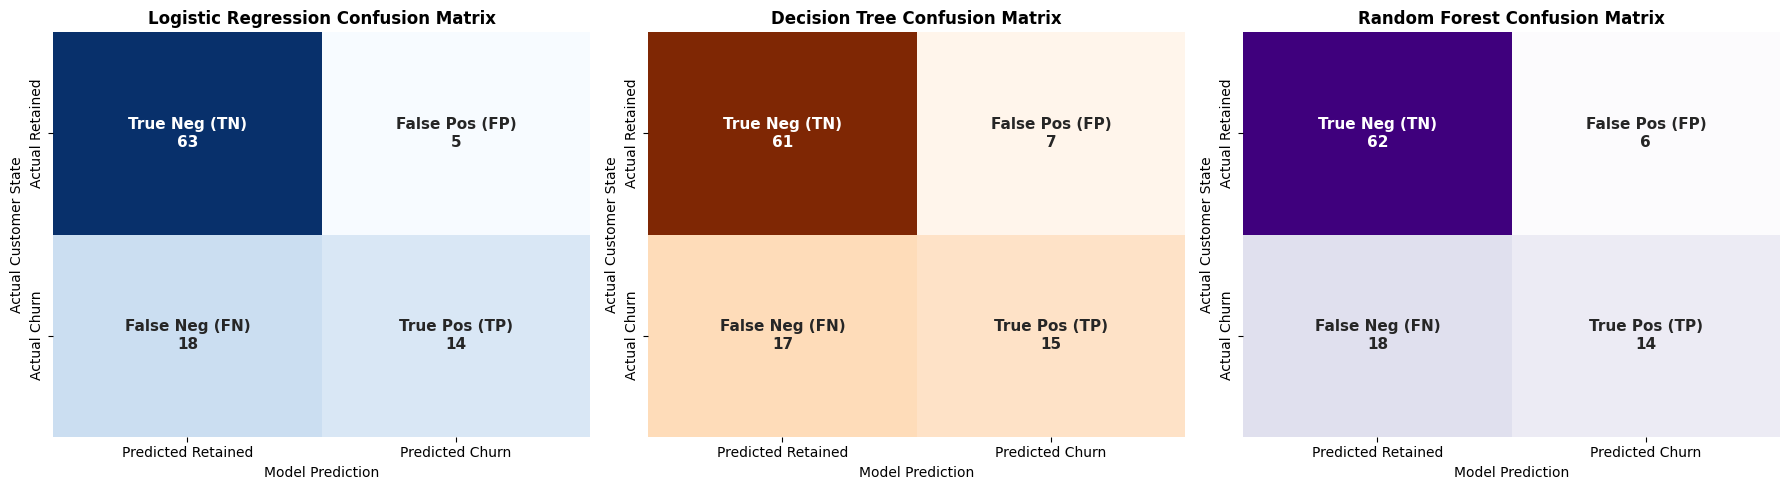

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_preds = [
    ('Logistic Regression', y_log_pred, 'Blues'),
    ('Decision Tree', y_dt_pred, 'Oranges'),
    ('Random Forest', y_rf_pred, 'Purples')
]

for i, (name, pred, cmap) in enumerate(models_preds):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    labels = np.array([
        [f"True Neg (TN)\n{tn}", f"False Pos (FP)\n{fp}"],
        [f"False Neg (FN)\n{fn}", f"True Pos (TP)\n{tp}"]
    ])
    sns.heatmap(cm, annot=labels, fmt='', cmap=cmap, cbar=False, ax=axes[i],
                xticklabels=['Predicted Retained', 'Predicted Churn'],
                yticklabels=['Actual Retained', 'Actual Churn'],
                annot_kws={"size": 11, "weight": "bold"})
    axes[i].set_title(f"{name} Confusion Matrix", fontweight='bold')
    axes[i].set_ylabel('Actual Customer State')
    axes[i].set_xlabel('Model Prediction')

plt.tight_layout()
plt.show()

### Proactive Performance and Customer Savings Assessment
We compile detailed classification metrics (**Accuracy**, **Precision**, **Recall**, and **F1-Score**) to evaluate performance, followed by the customer retention campaign cost-benefit balance sheets.

In [61]:
# Performance metrics table comparison
final_comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline Classifier': [
        accuracy_score(y_test, y_baseline_pred),
        precision_score(y_test, y_baseline_pred, zero_division=0),
        recall_score(y_test, y_baseline_pred, zero_division=0),
        f1_score(y_test, y_baseline_pred, zero_division=0)
    ],
    'Logistic Regression': [
        accuracy_score(y_test, y_log_pred),
        precision_score(y_test, y_log_pred, zero_division=0),
        recall_score(y_test, y_log_pred, zero_division=0),
        f1_score(y_test, y_log_pred, zero_division=0)
    ],
    'Decision Tree': [
        accuracy_score(y_test, y_dt_pred),
        precision_score(y_test, y_dt_pred, zero_division=0),
        recall_score(y_test, y_dt_pred, zero_division=0),
        f1_score(y_test, y_dt_pred, zero_division=0)
    ],
    'Random Forest': [
        accuracy_score(y_test, y_rf_pred),
        precision_score(y_test, y_rf_pred, zero_division=0),
        recall_score(y_test, y_rf_pred, zero_division=0),
        f1_score(y_test, y_rf_pred, zero_division=0)
    ]
})

print("=== PERFORMANCE COMPARISON TABLE ===")
display(final_comparison_df)

# Campaign financial savings calculation
log_tn, log_fp, log_fn, log_tp = confusion_matrix(y_test, y_log_pred).ravel()
dt_tn, dt_fp, dt_fn, dt_tp = confusion_matrix(y_test, y_dt_pred).ravel()
rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(y_test, y_rf_pred).ravel()

final_business_df = pd.DataFrame({
    'Strategy': [
        'Do Nothing',
        'Mass Outreach (All)',
        'Targeted (Logistic Regression)',
        'Targeted (Decision Tree)',
        'Targeted (Random Forest)'
    ],
    'Customers Targeted': [0, total_customers, (log_tp + log_fp), (dt_tp + dt_fp), (rf_tp + rf_fp)],
    'Campaign Cost': [0.0, total_cost_mass, (log_tp + log_fp) * cost_per_incentive, (dt_tp + dt_fp) * cost_per_incentive, (rf_tp + rf_fp) * cost_per_incentive],
    'Revenue Saved': [0.0, saved_revenue_mass, (log_tp * save_rate) * customer_lifetime_value, (dt_tp * save_rate) * customer_lifetime_value, (rf_tp * save_rate) * customer_lifetime_value],
    'Net Business Savings': [
        -loss_no_model,
        net_savings_mass - loss_no_model,
        ((log_tp * save_rate) * customer_lifetime_value) - ((log_tp + log_fp) * cost_per_incentive) - loss_no_model,
        ((dt_tp * save_rate) * customer_lifetime_value) - ((dt_tp + dt_fp) * cost_per_incentive) - loss_no_model,
        ((rf_tp * save_rate) * customer_lifetime_value) - ((rf_tp + rf_fp) * cost_per_incentive) - loss_no_model
    ]
})

print("\n=== PROACTIVE STRATEGY FINANCIAL IMPACT ===")
display(final_business_df)

# Determine and highlight the best model dynamically
best_accuracy_col = final_comparison_df.set_index('Metric').loc['Accuracy'].iloc[1:].astype(float).idxmax()
best_precision_col = final_comparison_df.set_index('Metric').loc['Precision'].iloc[1:].astype(float).idxmax()
best_saving_row = final_business_df.iloc[2:].loc[final_business_df['Net Business Savings'].idxmax()]

print(f"\n--- RECOMMENDATION ---")
print(f"* Best Model by Accuracy: {best_accuracy_col}")
print(f"* Best Model by Precision: {best_precision_col}")
print(f"* Top Financially Strategic Choice: {best_saving_row['Strategy']} (Net Business Savings: ${best_saving_row['Net Business Savings']:.2f})")

# Plot business comparison savings outcome
plt.figure(figsize=(12, 6))
sns.barplot(x='Strategy', y='Net Business Savings', hue='Strategy', data=final_business_df, palette='Set2', legend=False)
plt.title('Comparison of Proactive Customer Retention Strategies', fontsize=14, fontweight='bold')
plt.ylabel('Net Business Balance ($)', fontsize=12)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

=== PERFORMANCE COMPARISON TABLE ===


,Metric,Baseline Classifier,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.68,0.770000,0.760000,0.760000
1,Precision,0.00,0.736842,0.681818,0.700000
2,Recall,0.00,0.437500,0.468750,0.437500
3,F1-Score,0.00,0.549020,0.555556,0.538462



=== PROACTIVE STRATEGY FINANCIAL IMPACT ===


,Strategy,Customers Targeted,Campaign Cost,Revenue Saved,Net Business Savings
0,Do Nothing,0,0.0,0.0,-3200.0
1,Mass Outreach (All),100,1000.0,1600.0,-2600.0
2,Targeted (Logistic Regression),19,190.0,700.0,-2690.0
3,Targeted (Decision Tree),22,220.0,750.0,-2670.0
4,Targeted (Random Forest),20,200.0,700.0,-2700.0


KeyError: 1